# Transaction Risk Scoring Agent — training, evaluation, and SHAP explainability

Companion notebook for paper Sec. V-C ("Transaction Risk Scoring Agent"). Trains the real GradientBoostingClassifier used by `arca.layer1_intelligence.risk_scoring_agent`, reports held-out metrics, and inspects *why* the model scores specific transactions the way it does via SHAP (SHapley Additive exPlanations) — the explainability mechanism the paper's Sec. IV-C requires of every Layer 1 agent.

**On the training data**: see `data/README.md` for why this is a documented synthetic dataset rather than real account-level transaction data (real AML transaction data is confidential and cannot legally be redistributed here — this is exactly the empirical gap the paper's Sec. VII flags as future work).

In [1]:
import sys, pathlib
REPO_ROOT = pathlib.Path.cwd().parent if (pathlib.Path.cwd() / 'notebooks').exists() is False and (pathlib.Path.cwd().name == 'notebooks') else pathlib.Path.cwd()
if not (REPO_ROOT / 'arca').exists():
    REPO_ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))
print('Repo root:', REPO_ROOT)

Repo root: /home/claude/arca-prototype


In [2]:
import pathlib
import pandas as pd

data_path = REPO_ROOT / 'data' / 'synthetic_transactions.csv'
if not data_path.exists():
    import subprocess, sys
    subprocess.run([sys.executable, str(REPO_ROOT / 'scripts' / 'generate_synthetic_transactions.py')], check=True)

df = pd.read_csv(data_path)
print(df.shape)
df.head()

(8000, 12)


,amount,jurisdiction_tier,tx_velocity_24h,unique_counterparties_7d,account_age_days,cross_border,is_new_counterparty,hour_of_day,structuring_proximity,is_round_number,archetype,is_suspicious
0,5230.39,0,1,1,759,0,0,23,0.00,0.0,normal,1
1,753.74,0,2,3,161,1,0,13,0.00,0.0,normal,0
2,9200.00,0,5,3,169,0,0,0,0.68,1.0,structuring,0
3,2150.59,0,2,0,758,0,1,21,0.00,0.0,normal,0
4,1588.39,1,0,3,411,0,0,22,0.00,1.0,normal,0


## Class balance by latent archetype

Recall (see `data/README.md`) that the label is a *probabilistic* function of a hidden behavioural archetype, not a deterministic rule.

In [3]:
df.groupby('archetype')['is_suspicious'].agg(['mean', 'count'])

,mean,count
archetype,,
high_risk_corridor,0.820972,391
normal,0.039889,6819
rapid_layering,0.734628,309
structuring,0.727651,481


## Train the model and report held-out metrics

In [4]:
from arca.layer1_intelligence.risk_scoring_agent import train_model, FEATURE_COLUMNS

metrics = train_model()
metrics

{'roc_auc': 0.8681356469154022,
 'average_precision': 0.6602492742304399,
 'n_train': 6000,
 'n_test': 2000,
 'positive_rate_test': 0.146}

A random / no-signal classifier has ROC-AUC ≈ 0.5. The model above shows substantial, genuine separation without being suspiciously perfect (which would suggest the label is just a memorized restatement of the features).

## SHAP explainability

Global feature importance (mean |SHAP value|) across the held-out set, and a look at two contrasting individual transactions.

In [5]:
import joblib
import shap
import numpy as np
from sklearn.model_selection import train_test_split

model = joblib.load(REPO_ROOT / 'data' / 'risk_model.joblib')
X = df[FEATURE_COLUMNS]
y = df['is_suspicious']
_, X_test, _, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap_values.shape

(2000, 10)

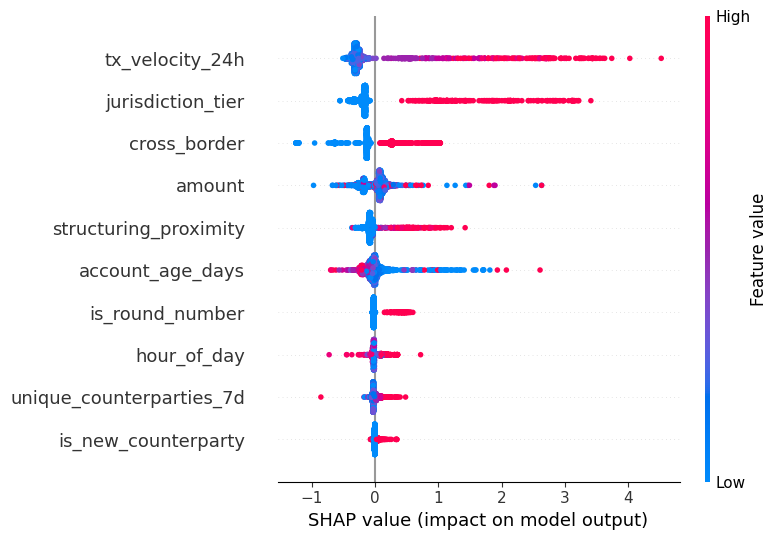

In [6]:
import matplotlib.pyplot as plt

shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig(REPO_ROOT / 'notebooks' / 'shap_summary.png', dpi=120, bbox_inches='tight')
plt.show()

## Two contrasting transactions, explained

Reproduces exactly what `TransactionRiskScoringAgent.score()` returns as a CRR's `reasoning_trace` — this is the real code path, not a notebook-only shortcut.

In [7]:
from arca.layer1_intelligence.risk_scoring_agent import TransactionRiskScoringAgent
from arca.layer2_identity.did_registry import generate_did

agent = TransactionRiskScoringAgent(generate_did())

normal_tx = {'amount': 4200.0, 'jurisdiction_tier': 0, 'tx_velocity_24h': 1, 'unique_counterparties_7d': 2,
             'account_age_days': 900, 'cross_border': 0, 'is_new_counterparty': 0, 'hour_of_day': 14,
             'structuring_proximity': 0.0, 'is_round_number': 0.0}
struct_tx = {'amount': 9500.0, 'jurisdiction_tier': 1, 'tx_velocity_24h': 6, 'unique_counterparties_7d': 2,
             'account_age_days': 20, 'cross_border': 1, 'is_new_counterparty': 1, 'hour_of_day': 2,
             'structuring_proximity': 0.9, 'is_round_number': 1.0}

for label, tx in [('Normal-looking', normal_tx), ('Structuring-like', struct_tx)]:
    crr = agent.score(f'NB-{label}', tx)
    print(f'--- {label} (score={crr.outcome:.3f}) ---')
    for line in crr.reasoning_trace:
        print('  -', line)
    print()

--- Normal-looking (score=0.036) ---
  - Calibrated risk score: 0.036 (0=low risk, 1=high risk).
  - Feature 'tx_velocity_24h' = 1 decreased the risk score by 0.297 (SHAP attribution).
  - Feature 'jurisdiction_tier' = 0 decreased the risk score by 0.154 (SHAP attribution).
  - Feature 'cross_border' = 0 decreased the risk score by 0.129 (SHAP attribution).

--- Structuring-like (score=0.790) ---
  - Calibrated risk score: 0.790 (0=low risk, 1=high risk).
  - Feature 'tx_velocity_24h' = 6 increased the risk score by 1.449 (SHAP attribution).
  - Feature 'account_age_days' = 20 increased the risk score by 0.853 (SHAP attribution).
  - Feature 'jurisdiction_tier' = 1 increased the risk score by 0.791 (SHAP attribution).

